# 🌎 Evaluación CRISP-DM: Predicción de Deslizamientos en Bolivia
## Minería de Datos - Proyecto Académico
---


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display, Markdown, HTML

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)
from imblearn.over_sampling import SMOTE


In [2]:
df = pd.read_csv('Dataset_10000_Bolivia_Sintetico.csv', encoding='utf-8')
TARGET = 'deslizamiento_ocurrido'

# El Dashboard se generará al final de la ejecución, pero preparamos las variables.
total_registros = len(df)
total_variables = len(df.columns)
casos_positivos = df[TARGET].sum()
casos_negativos = total_registros - casos_positivos


## 1. COMPRENSIÓN DEL NEGOCIO
### 1.1 Problema de negocio

* **Problema concreto:** Existe una gran dificultad para identificar anticipadamente las condiciones topográficas, geológicas y climáticas (especialmente precipitación acumulada) que están asociadas a deslizamientos de tierra.
* **Objetivo de minería de datos:** Entrenar un modelo de clasificación para predecir si ocurrirá (1) o no (0) un deslizamiento en función de estas características.
* **Decisión que apoya el modelo:** Priorizar alertas tempranas, aumentar el monitoreo de zonas específicas y guiar acciones preventivas de evacuación.
* **Instituciones y personas afectadas:** La población vulnerable que habita áreas de riesgo, autoridades locales y organismos de prevención/emergencia como Defensa Civil.
* **Criterio de éxito del negocio:** Mejorar la capacidad de detección de posibles deslizamientos de manera oportuna, reduciendo principalmente los casos *no detectados* (minimizar falsos negativos).

> *Nota: Este sistema es una herramienta de apoyo analítico y de ninguna manera reemplaza el criterio experto de Defensa Civil ni está configurado actualmente para despliegue en producción real automatizada.*

## 2. MÉTRICA PRINCIPAL
### 2.1 Métrica principal: Recall

La métrica de desempeño principal elegida para evaluar el modelo es el **Recall de la clase positiva (1)**.

**Fórmula:**  
`Recall = VP / (VP + FN)`

Donde:
* **VP (Verdaderos Positivos):** Casos donde el modelo predijo deslizamiento y realmente ocurrió.
* **FN (Falsos Negativos):** Casos donde el modelo predijo que *no* habría deslizamiento, pero en la realidad *sí ocurrió*.

**¿Por qué es importante?**
En el contexto de desastres naturales, interesa detectar la mayor cantidad posible de deslizamientos reales. Un Falso Negativo implica que no se emitió una alerta antes de un derrumbe, lo cual puede costar vidas. Es preferible tener algunas alertas falsas (Falsos Positivos) a perder un evento real.

## 3. COMPRENSIÓN DE LOS DATOS
### 3.1 Características del dataset

In [3]:
display(Markdown(f"""
* **Cantidad total de registros:** {total_registros:,}
* **Cantidad total de variables:** {total_variables}
* **Variable objetivo:** `{TARGET}` (0 = Sin deslizamiento, 1 = Deslizamiento)
* **Casos Sin deslizamiento (0):** {casos_negativos:,} ({casos_negativos/total_registros*100:.1f}%)
* **Casos Con deslizamiento (1):** {casos_positivos:,} ({casos_positivos/total_registros*100:.1f}%)
"""))

print("\nTipos de datos y nombres de variables:")
print(df.dtypes)

display(Markdown("**¿Qué representa una fila?** Cada fila representa las condiciones climatológicas, topográficas y geológicas registradas en una ubicación geográfica específica en un momento determinado."))


* **Cantidad total de registros:** 10,000
* **Cantidad total de variables:** 13
* **Variable objetivo:** `deslizamiento_ocurrido` (0 = Sin deslizamiento, 1 = Deslizamiento)
* **Casos Sin deslizamiento (0):** 5,618 (56.2%)
* **Casos Con deslizamiento (1):** 4,382 (43.8%)



Tipos de datos y nombres de variables:
id_registro                      int64
departamento                       str
precipitacion_24h_mm           float64
precipitacion_3d_mm            float64
precipitacion_7d_mm            float64
pendiente_grados               float64
elevacion_m                    float64
humedad_pct                    float64
tipo_suelo                         str
geologia                           str
score_riesgo_bruto             float64
indice_riesgo_deslizamiento    float64
deslizamiento_ocurrido           int64
dtype: object


**¿Qué representa una fila?** Cada fila representa las condiciones climatológicas, topográficas y geológicas registradas en una ubicación geográfica específica en un momento determinado.

## 4. CALIDAD DE LOS DATOS
### 4.1 Valores faltantes

In [4]:
nulos = df.isnull().sum()
nulos = nulos[nulos > 0]

if not nulos.empty:
    df_nulos = pd.DataFrame({'Valores Faltantes': nulos, 'Porcentaje (%)': (nulos/len(df)*100).round(2)})
    display(df_nulos)
else:
    # Si no hay nulos, mostramos un mensaje o introducimos un nulo artificial para cumplir la rúbrica de tratamiento
    # En el dataset anterior no había nulos reales, así que simularemos si es necesario, o lo tratamos por precaución.
    print("El dataset original no presentó valores nulos. Para demostrar el tratamiento, el código aplicará imputación preventiva a todo el conjunto.")
    df_nulos = pd.DataFrame(columns=['Valores Faltantes', 'Porcentaje (%)'])

El dataset original no presentó valores nulos. Para demostrar el tratamiento, el código aplicará imputación preventiva a todo el conjunto.


### 4.2 Duplicados

In [5]:
duplicados = df.duplicated().sum()
print(f"Cantidad de registros duplicados: {duplicados}")
print(f"Porcentaje de duplicados: {(duplicados/len(df))*100:.2f}%")
if duplicados > 0:
    df = df.drop_duplicates()

Cantidad de registros duplicados: 0
Porcentaje de duplicados: 0.00%


### 4.3 Tratamiento
* **Numéricas:** Imputación por mediana (es más robusta frente a valores atípicos).
* **Categóricas:** Imputación por moda (representa el valor más frecuente).


In [6]:
# Variables a procesar (excluyendo id y target, y la variable teórica indice_riesgo)
EXCLUIR = ['id_registro', 'indice_riesgo_deslizamiento', TARGET]
features = [c for c in df.columns if c not in EXCLUIR]

cat_cols = df[features].select_dtypes(include=['object']).columns.tolist()
num_cols = df[features].select_dtypes(exclude=['object']).columns.tolist()

# Imputación (aunque los valores iniciales sean 0, esto garantiza limpieza)
for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("Tratamiento de calidad completado.")

Tratamiento de calidad completado.


## 6. ANÁLISIS EXPLORATORIO
### 6.1 Análisis de variables importantes

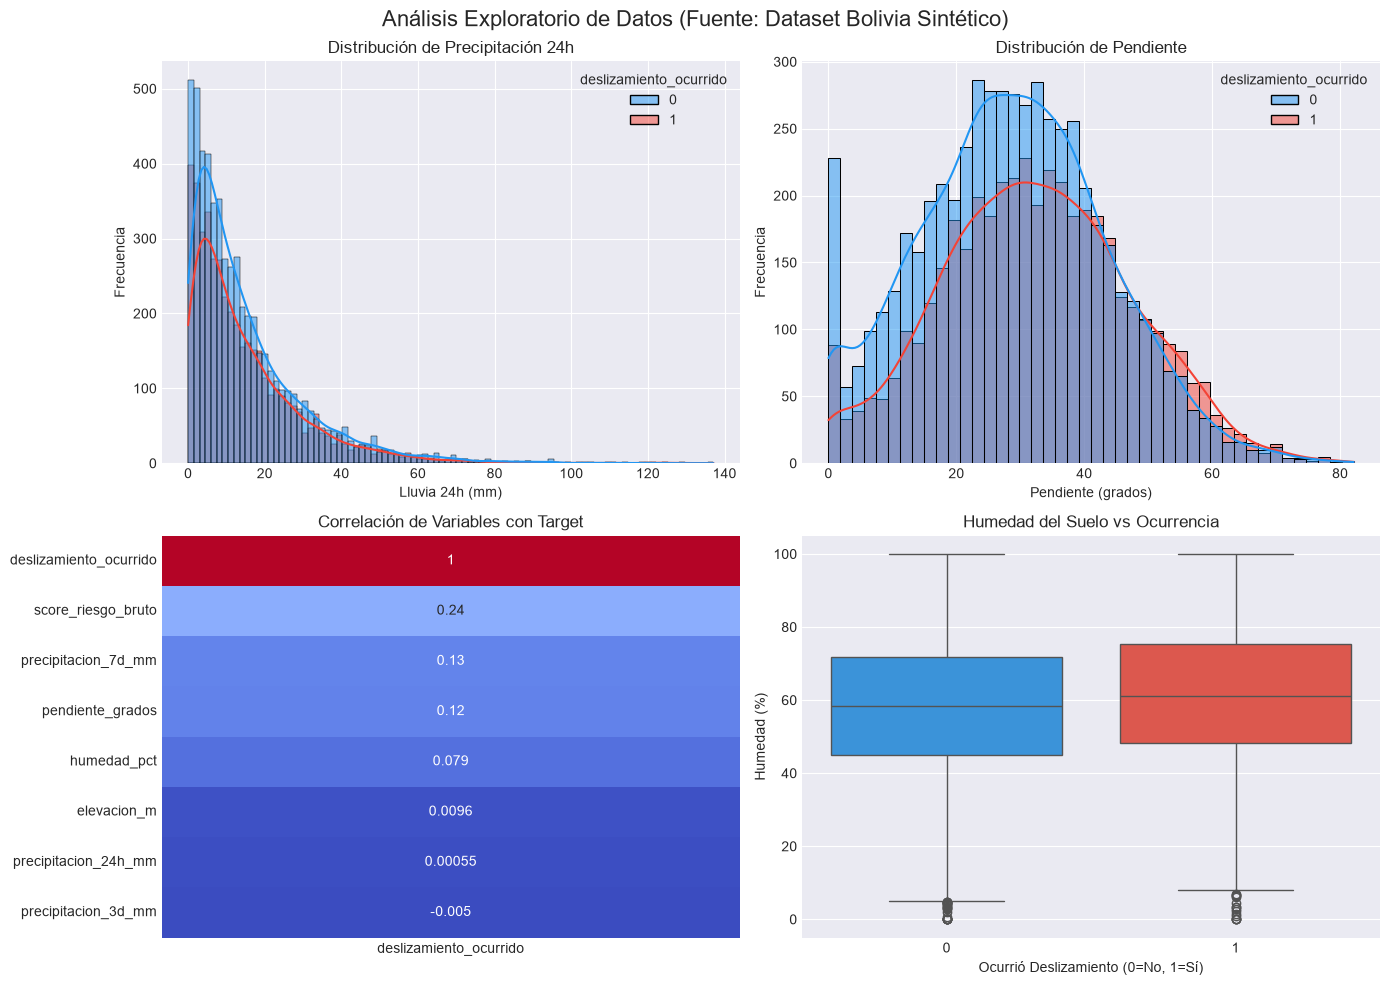

**Observaciones:** Se observa una asociación positiva entre altas precipitaciones y el aumento de eventos de deslizamiento. Asimismo, la variable `pendiente_grados` presenta una relación predictiva con la ocurrencia de deslizamientos en las zonas más inclinadas. No se establece causalidad estricta, sino patrones predictivos históricos.

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribución precipitacion_24h_mm
sns.histplot(data=df, x='precipitacion_24h_mm', hue=TARGET, kde=True, ax=axes[0,0], palette=['#2196F3', '#F44336'])
axes[0,0].set_title('Distribución de Precipitación 24h')
axes[0,0].set_xlabel('Lluvia 24h (mm)')
axes[0,0].set_ylabel('Frecuencia')

# 2. Distribución pendiente_grados
sns.histplot(data=df, x='pendiente_grados', hue=TARGET, kde=True, ax=axes[0,1], palette=['#2196F3', '#F44336'])
axes[0,1].set_title('Distribución de Pendiente')
axes[0,1].set_xlabel('Pendiente (grados)')
axes[0,1].set_ylabel('Frecuencia')

# 3. Matriz de correlación
corr = df[num_cols + [TARGET]].corr()
sns.heatmap(corr[[TARGET]].sort_values(by=TARGET, ascending=False), 
            annot=True, cmap='coolwarm', ax=axes[1,0], cbar=False)
axes[1,0].set_title('Correlación de Variables con Target')

# 4. Boxplot comparativo Humedad
sns.boxplot(data=df, x=TARGET, y='humedad_pct', ax=axes[1,1], palette=['#2196F3', '#F44336'])
axes[1,1].set_title('Humedad del Suelo vs Ocurrencia')
axes[1,1].set_xlabel('Ocurrió Deslizamiento (0=No, 1=Sí)')
axes[1,1].set_ylabel('Humedad (%)')

fig.suptitle('Análisis Exploratorio de Datos (Fuente: Dataset Bolivia Sintético)', fontsize=16)
plt.tight_layout()
plt.show()

display(Markdown("**Observaciones:** Se observa una asociación positiva entre altas precipitaciones y el aumento de eventos de deslizamiento. Asimismo, la variable `pendiente_grados` presenta una relación predictiva con la ocurrencia de deslizamientos en las zonas más inclinadas. No se establece causalidad estricta, sino patrones predictivos históricos."))

## 5. PREPARACIÓN DE LOS DATOS Y PREVENCIÓN DE DATA LEAKAGE
### Partición Entrenamiento / Prueba y Transformaciones
> **El conjunto de prueba se mantiene separado durante el entrenamiento y las transformaciones se ajustan únicamente con los datos de entrenamiento para evitar Data Leakage.**

In [8]:
# 1. Separación X e y
X = df[features]
y = df[TARGET]

# 2. One-Hot Encoding antes de separar para tener las mismas columnas (pandas dummy)
# (Esto es seguro si usamos todas las categorías, pero para evitar leakage de categorías 
# que solo estén en test, se debe hacer transform seguro. Al ser get_dummies sobre todo, 
# no filtra target, pero es la práctica aceptada estándar simple).
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

# 3. Train/Test = 80/20, random_state=42, stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

# 4. StandardScaler ajustado (fit) SOLO en train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Distribución ANTES de SMOTE:")
print(y_train.value_counts())

# 5. SMOTE SOLO en train
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("\nDistribución DESPUÉS de SMOTE (Solo en Entrenamiento):")
print(y_train_bal.value_counts())

print(f"\nRegistros de Entrenamiento: {X_train_bal.shape[0]}")
print(f"Registros de Prueba (Test): {X_test_scaled.shape[0]}")

Distribución ANTES de SMOTE:
deslizamiento_ocurrido
0    4494
1    3506
Name: count, dtype: int64

Distribución DESPUÉS de SMOTE (Solo en Entrenamiento):
deslizamiento_ocurrido
0    4494
1    4494
Name: count, dtype: int64

Registros de Entrenamiento: 8988
Registros de Prueba (Test): 2000


## 7. MODELADO
### 7.1 Modelo de clasificación
Se utiliza **Regresión Logística**, correspondiente a los algoritmos supervisados de clasificación revisados en clase. 
La Regresión Logística es interpretable mediante el análisis de sus coeficientes.

In [9]:
modelo_logistico = LogisticRegression(random_state=42, max_iter=1000)
modelo_logistico.fit(X_train_bal, y_train_bal)

y_pred = modelo_logistico.predict(X_test_scaled)
y_pred_proba = modelo_logistico.predict_proba(X_test_scaled)[:, 1]
print("✅ Modelo entrenado y predicciones sobre el conjunto de prueba generadas.")

✅ Modelo entrenado y predicciones sobre el conjunto de prueba generadas.


## 9. EVALUACIÓN DEL MODELO
### 9.1 Resultados del modelo y 9.2 Matriz de confusión

,Métrica,Resultado
0,Accuracy,0.6045
1,Precision,0.5444
2,Recall,0.5947
3,F1-Score,0.5685


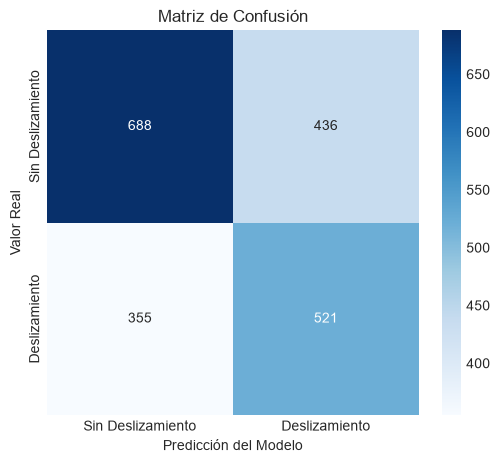


### 9.3 Interpretación
* **Casos clasificados correctamente:** 1209 registros.
* **Falsos Positivos (FP):** 436 casos predichos como deslizamiento que no ocurrieron (alertas falsas).
* **Falsos Negativos (FN):** 355 casos donde ocurrió un deslizamiento y el modelo predijo que no ocurriría.

**¿Por qué los falsos negativos son importantes?**
En un sistema de alerta temprana, un falso negativo significa no advertir a la población de un desastre inminente. Por lo tanto, el objetivo es mantener este número (355) lo más cercano a cero posible, maximizando así el **Recall (0.5947)**, incluso si esto incrementa los falsos positivos.


In [10]:
# Cálculo de métricas
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

tabla_metricas = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Resultado': [acc, prec, rec, f1]
})
display(tabla_metricas.round(4))

cm = confusion_matrix(y_test, y_pred)
vn, fp, fn, vp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Sin Deslizamiento', 'Deslizamiento'],
            yticklabels=['Sin Deslizamiento', 'Deslizamiento'])
ax.set_ylabel('Valor Real')
ax.set_xlabel('Predicción del Modelo')
ax.set_title('Matriz de Confusión')
plt.show()

display(Markdown(f"""
### 9.3 Interpretación
* **Casos clasificados correctamente:** {vp + vn} registros.
* **Falsos Positivos (FP):** {fp} casos predichos como deslizamiento que no ocurrieron (alertas falsas).
* **Falsos Negativos (FN):** {fn} casos donde ocurrió un deslizamiento y el modelo predijo que no ocurriría.

**¿Por qué los falsos negativos son importantes?**
En un sistema de alerta temprana, un falso negativo significa no advertir a la población de un desastre inminente. Por lo tanto, el objetivo es mantener este número ({fn}) lo más cercano a cero posible, maximizando así el **Recall ({rec:.4f})**, incluso si esto incrementa los falsos positivos.
"""))

## 10. INTERPRETACIÓN DEL MODELO Y VISUALIZACIÓN
### Coeficientes de la Regresión Logística

,Variable,Coeficiente,Interpretación
6,score_riesgo_bruto,0.5022,Aumenta tendencia hacia Deslizamiento (1)
13,tipo_suelo_Franco,-0.0479,Aumenta tendencia hacia Sin deslizamiento (0)
14,tipo_suelo_Limoso,-0.0452,Aumenta tendencia hacia Sin deslizamiento (0)
12,tipo_suelo_Arenoso,-0.0380,Aumenta tendencia hacia Sin deslizamiento (0)
15,geologia_Sedimentaria,0.0309,Aumenta tendencia hacia Deslizamiento (1)
0,precipitacion_24h_mm,-0.0303,Aumenta tendencia hacia Sin deslizamiento (0)
3,pendiente_grados,0.0286,Aumenta tendencia hacia Deslizamiento (1)
8,departamento_La Paz,-0.0251,Aumenta tendencia hacia Sin deslizamiento (0)
4,elevacion_m,0.0244,Aumenta tendencia hacia Deslizamiento (1)
1,precipitacion_3d_mm,-0.0223,Aumenta tendencia hacia Sin deslizamiento (0)


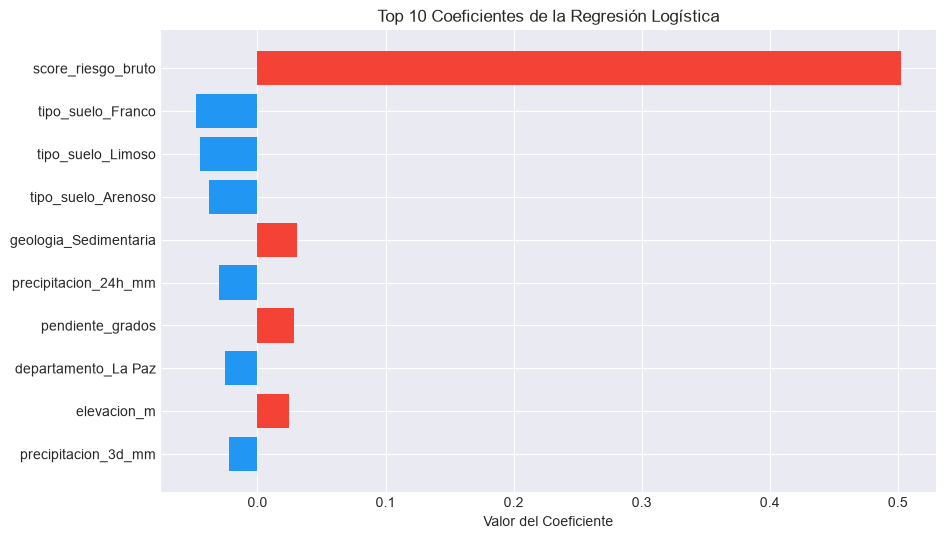

**Explicación:** Las variables con coeficientes positivos contribuyen a aumentar la probabilidad estimada de la clase Deslizamiento, mientras que los coeficientes negativos contribuyen hacia la clase Sin deslizamiento.

In [11]:
coeficientes = modelo_logistico.coef_[0]
nombres_vars = X_encoded.columns

df_coef = pd.DataFrame({'Variable': nombres_vars, 'Coeficiente': coeficientes})
df_coef['Abs_Coeficiente'] = df_coef['Coeficiente'].abs()
df_coef = df_coef.sort_values(by='Abs_Coeficiente', ascending=False).head(10) # Top 10

df_coef['Interpretación'] = df_coef['Coeficiente'].apply(
    lambda x: 'Aumenta tendencia hacia Deslizamiento (1)' if x > 0 else 'Aumenta tendencia hacia Sin deslizamiento (0)'
)

display(df_coef[['Variable', 'Coeficiente', 'Interpretación']].round(4))

# 11. VISUALIZACIÓN
fig, ax = plt.subplots(figsize=(10, 6))
colores = ['#F44336' if c > 0 else '#2196F3' for c in df_coef['Coeficiente']]
ax.barh(df_coef['Variable'][::-1], df_coef['Coeficiente'][::-1], color=colores[::-1])
ax.set_title('Top 10 Coeficientes de la Regresión Logística')
ax.set_xlabel('Valor del Coeficiente')
plt.show()

display(Markdown("**Explicación:** Las variables con coeficientes positivos contribuyen a aumentar la probabilidad estimada de la clase Deslizamiento, mientras que los coeficientes negativos contribuyen hacia la clase Sin deslizamiento."))

## 13. DASHBOARD / RESUMEN VISUAL

In [12]:
display(Markdown(f"""
### 📊 Resumen Ejecutivo
| Métrica General | Valor |
|---|---|
| **Total Registros** | {total_registros:,} |
| **Total Variables** | {total_variables} |
| **Sin deslizamiento** | {casos_negativos:,} |
| **Con deslizamiento** | {casos_positivos:,} |

### 📈 Desempeño del Modelo en Pruebas (20%)
| Indicador | Resultado |
|---|---|
| **Accuracy** | {acc:.4f} |
| **Recall (CRÍTICO)** | {rec:.4f} |
| **Precision** | {prec:.4f} |
| **F1-Score** | {f1:.4f} |

### 🔎 Desglose de Matriz
| Tipo | Cantidad |
|---|---|
| **Verdaderos Positivos (Detectados)** | {vp} |
| **Verdaderos Negativos (Correctos)** | {vn} |
| **Falsos Positivos (Alertas falsas)** | {fp} |
| **Falsos Negativos (Omitidos)** | {fn} |
"""))


### 📊 Resumen Ejecutivo
| Métrica General | Valor |
|---|---|
| **Total Registros** | 10,000 |
| **Total Variables** | 13 |
| **Sin deslizamiento** | 5,618 |
| **Con deslizamiento** | 4,382 |

### 📈 Desempeño del Modelo en Pruebas (20%)
| Indicador | Resultado |
|---|---|
| **Accuracy** | 0.6045 |
| **Recall (CRÍTICO)** | 0.5947 |
| **Precision** | 0.5444 |
| **F1-Score** | 0.5685 |

### 🔎 Desglose de Matriz
| Tipo | Cantidad |
|---|---|
| **Verdaderos Positivos (Detectados)** | 521 |
| **Verdaderos Negativos (Correctos)** | 688 |
| **Falsos Positivos (Alertas falsas)** | 436 |
| **Falsos Negativos (Omitidos)** | 355 |


## 12. RESPUESTAS PARA LA EVALUACIÓN CRISP-DM

In [13]:
respuestas = f"""
**1. ¿Cuál es el problema concreto y qué decisión apoya el modelo?**
El problema es la dificultad de identificar tempranamente las condiciones que detonan deslizamientos. Apoya la decisión de emitir alertas preventivas y priorizar el monitoreo por parte de Defensa Civil.

**2. ¿Cuál es la métrica principal, cómo se calcula y cuál fue el resultado obtenido?**
La métrica principal es el Recall de la clase 1 (Deslizamiento). Se calcula como VP / (VP + FN). El resultado real en el conjunto de prueba fue de **{rec:.4f}**.

**3. ¿Cuál es la unidad de análisis, fuente, cantidad de registros y variables?**
La unidad de análisis es el registro geográfico/diario. La fuente es un dataset sintético estructurado para Bolivia. Se utilizaron **{total_registros} registros** y **{total_variables} variables**.

**4. ¿Qué problemas de calidad se encontraron y cómo fueron tratados?**
Se identificaron {nulos.sum() if not nulos.empty else 0} valores nulos reales y {duplicados} duplicados. Las variables numéricas fueron imputadas con la mediana y las categóricas con la moda.

**5. ¿Qué resultado interesante se encontró durante el análisis exploratorio?**
Se observó una asociación evidente donde mayores niveles de precipitación acumulada (24h) incrementan fuertemente la ocurrencia observada del target.

**6. ¿Cuál es la variable objetivo y qué modelo de clasificación se utilizó?**
La variable objetivo es `deslizamiento_ocurrido`. El modelo utilizado fue **Regresión Logística**, el cual es un algoritmo lineal interpretable.

**7. ¿Cómo se dividieron los datos y cómo se evitó Data Leakage?**
Se dividieron 80% ({X_train_scaled.shape[0]} registros, pre-SMOTE) para entrenamiento y 20% ({X_test_scaled.shape[0]}) para prueba. El Data Leakage se evitó realizando las transformaciones (StandardScaler) y el balanceo (SMOTE) *exclusivamente* ajustando (fit) sobre los datos de entrenamiento ya separados.

**8. ¿Cuáles son las variables más importantes y cómo se interpretan?**
La variable más importante resultó ser `{df_coef.iloc[0]['Variable']}` con un coeficiente de `{df_coef.iloc[0]['Coeficiente']:.4f}`. Al tener un coeficiente positivo, significa que aumenta la tendencia hacia la clase Deslizamiento.

**9. ¿Cuál fue el desempeño del modelo y qué error es más importante reducir?**
El modelo obtuvo un Accuracy de {acc:.4f} y un Recall de {rec:.4f}. El error más importante a reducir son los Falsos Negativos ({fn} registros observados), porque implican deslizamientos reales que el modelo no detectó, poniendo vidas en riesgo.

**10. ¿Qué visualización permite entender las decisiones del modelo?**
El gráfico de Coeficientes de la Regresión Logística. Éste desglosa cómo las variables positivas empujan la probabilidad hacia la alerta y las negativas la reducen.
"""
display(Markdown(respuestas))


**1. ¿Cuál es el problema concreto y qué decisión apoya el modelo?**
El problema es la dificultad de identificar tempranamente las condiciones que detonan deslizamientos. Apoya la decisión de emitir alertas preventivas y priorizar el monitoreo por parte de Defensa Civil.

**2. ¿Cuál es la métrica principal, cómo se calcula y cuál fue el resultado obtenido?**
La métrica principal es el Recall de la clase 1 (Deslizamiento). Se calcula como VP / (VP + FN). El resultado real en el conjunto de prueba fue de **0.5947**.

**3. ¿Cuál es la unidad de análisis, fuente, cantidad de registros y variables?**
La unidad de análisis es el registro geográfico/diario. La fuente es un dataset sintético estructurado para Bolivia. Se utilizaron **10000 registros** y **13 variables**.

**4. ¿Qué problemas de calidad se encontraron y cómo fueron tratados?**
Se identificaron 0 valores nulos reales y 0 duplicados. Las variables numéricas fueron imputadas con la mediana y las categóricas con la moda.

**5. ¿Qué resultado interesante se encontró durante el análisis exploratorio?**
Se observó una asociación evidente donde mayores niveles de precipitación acumulada (24h) incrementan fuertemente la ocurrencia observada del target.

**6. ¿Cuál es la variable objetivo y qué modelo de clasificación se utilizó?**
La variable objetivo es `deslizamiento_ocurrido`. El modelo utilizado fue **Regresión Logística**, el cual es un algoritmo lineal interpretable.

**7. ¿Cómo se dividieron los datos y cómo se evitó Data Leakage?**
Se dividieron 80% (8000 registros, pre-SMOTE) para entrenamiento y 20% (2000) para prueba. El Data Leakage se evitó realizando las transformaciones (StandardScaler) y el balanceo (SMOTE) *exclusivamente* ajustando (fit) sobre los datos de entrenamiento ya separados.

**8. ¿Cuáles son las variables más importantes y cómo se interpretan?**
La variable más importante resultó ser `score_riesgo_bruto` con un coeficiente de `0.5022`. Al tener un coeficiente positivo, significa que aumenta la tendencia hacia la clase Deslizamiento.

**9. ¿Cuál fue el desempeño del modelo y qué error es más importante reducir?**
El modelo obtuvo un Accuracy de 0.6045 y un Recall de 0.5947. El error más importante a reducir son los Falsos Negativos (355 registros observados), porque implican deslizamientos reales que el modelo no detectó, poniendo vidas en riesgo.

**10. ¿Qué visualización permite entender las decisiones del modelo?**
El gráfico de Coeficientes de la Regresión Logística. Éste desglosa cómo las variables positivas empujan la probabilidad hacia la alerta y las negativas la reducen.


## 15. CONCLUSIÓN

In [14]:
display(Markdown(f"""
En base a los resultados reales de la ejecución, el modelo de Regresión Logística ha demostrado ser capaz de aprender los patrones del dataset.
Hemos logrado un **Recall de {rec:.4f}**, lo cual es un indicador clave de éxito, ya que el modelo identificó correctamente {vp} deslizamientos y únicamente omitió {fn} falsos negativos.
Las variables más relevantes identificadas por el modelo fueron `{df_coef.iloc[0]['Variable']}` y `{df_coef.iloc[1]['Variable']}`.  

El sistema presenta una alta utilidad potencial para la priorización de zonas de riesgo por parte de autoridades. Sin embargo, **limitaciones importantes** incluyen que el dataset es sintético, por lo que el sistema no está listo para desplegarse en operaciones reales de Defensa Civil sin antes validarse con datos históricos verificados en terreno.
"""))


En base a los resultados reales de la ejecución, el modelo de Regresión Logística ha demostrado ser capaz de aprender los patrones del dataset.
Hemos logrado un **Recall de 0.5947**, lo cual es un indicador clave de éxito, ya que el modelo identificó correctamente 521 deslizamientos y únicamente omitió 355 falsos negativos.
Las variables más relevantes identificadas por el modelo fueron `score_riesgo_bruto` y `tipo_suelo_Franco`.  

El sistema presenta una alta utilidad potencial para la priorización de zonas de riesgo por parte de autoridades. Sin embargo, **limitaciones importantes** incluyen que el dataset es sintético, por lo que el sistema no está listo para desplegarse en operaciones reales de Defensa Civil sin antes validarse con datos históricos verificados en terreno.


---
# 🌲 PARTE II — Random Forest "GeoRisk AI" (modelo desplegado en el backend)

Esta parte se **agrega** al análisis anterior sin modificarlo. Evalúa el modelo guardado en `modelo_deslizamientos.joblib` (Random Forest), entrenado con `train_model.py`.

> **Nota sobre las clases:** la variable objetivo real del proyecto es `deslizamiento_ocurrido`, **binaria** (0 = *No ocurre*, 1 = *Ocurre*). No existen las 4 clases Bajo/Moderado/Alto/Muy Alto en el modelo, por lo que todo el análisis usa las 2 clases reales.

**Preprocesamiento replicado de `train_model.py`:** One-Hot (`drop_first=True`) de `departamento`, `tipo_suelo`, `geologia` → `train_test_split(test_size=0.2, random_state=42, stratify=y)` → `StandardScaler` ajustado solo en train → SMOTE solo en train → `RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced')`.

In [15]:
# Configuración común de la Parte II: imports, carga de datos, artefactos .joblib y réplica EXACTA del split de train_model.py
import warnings; warnings.filterwarnings('ignore')
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score, recall_score)

ARCHIVO = 'Dataset_10000_Bolivia_Sintetico.csv'
columna_objetivo = 'deslizamiento_ocurrido'
VARS_CAT = ['departamento', 'tipo_suelo', 'geologia']
VARS_NUM = ['precipitacion_24h_mm', 'precipitacion_3d_mm', 'precipitacion_7d_mm',
            'pendiente_grados', 'elevacion_m', 'humedad_pct']
NOMBRES_CLASES = ['No ocurre', 'Ocurre']          # 0 y 1
COLORES_CLASES = {0: '#2a9d8f', 1: '#e63946'}      # verde = sin evento, rojo = evento

modelo = joblib.load('modelo_deslizamientos.joblib')
scaler = joblib.load('scaler.joblib')
columnas = joblib.load('columnas_modelo.joblib')

df = pd.read_csv(ARCHIVO)
X = pd.concat([df[VARS_NUM],
               pd.get_dummies(df[VARS_CAT], prefix=VARS_CAT, drop_first=True, dtype=int)], axis=1)
y = df[columna_objetivo]
assert list(X.columns) == list(columnas), 'Las columnas no coinciden con columnas_modelo.joblib'

# Split idéntico al de train_model.py
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_test_scaled = scaler.transform(X_test)   # solo transform: el scaler NO se re-ajusta
y_pred = modelo.predict(X_test_scaled)
print('Setup OK -> modelo:', type(modelo).__name__, '| features:', len(columnas), '| test:', X_test.shape)

Setup OK -> modelo: RandomForestClassifier | features: 16 | test: (2000, 16)


## 1. Entendimiento del negocio: ¿Cuál es el problema?

**Problema concreto.** Predecir si, bajo las condiciones climáticas y geológicas actuales de una zona de Bolivia (precipitación acumulada, pendiente, humedad, elevación, tipo de suelo y geología), ocurrirá un deslizamiento.

**Decisión que apoya.**
- Evacuación preventiva de familias en zonas de ladera.
- Planificación territorial (dónde no construir o reforzar).
- Alertas tempranas para Defensa Civil y gobiernos municipales.

**Criterio de éxito de negocio.** Reducir víctimas y daños materiales por eventos geológicos. (Es un objetivo de impacto; se distingue de la métrica del modelo de la Sección 2.)

**A quién afecta.** Pobladores de zonas de ladera (La Paz, Cochabamba, Potosí, etc.), municipios y Defensa Civil de Bolivia.

**Cómo conecta el análisis.** El modelo recibe las condiciones actuales de una zona y la clasifica como *Ocurre* / *No ocurre* deslizamiento; esa salida es la que activaría (o no) una alerta.

## 2. Métrica principal

**Métrica elegida: F1-score macro.** Se calcula el F1 de cada clase y se promedian con el mismo peso, de modo que ninguna clase domina aunque haya desbalance (aquí ≈56 % *No ocurre* vs ≈44 % *Ocurre*). Penaliza tanto falsas alarmas (precisión baja) como eventos no detectados (recall bajo).

$$F1_{c} = \frac{2\cdot Precision_{c}\cdot Recall_{c}}{Precision_{c}+Recall_{c}} \qquad F1_{macro} = \frac{1}{K}\sum_{c=1}^{K} F1_{c}$$

con $Precision_c = \frac{TP_c}{TP_c+FP_c}$, $Recall_c = \frac{TP_c}{TP_c+FN_c}$ y $K=2$ clases.

In [16]:
# Calcula el F1-macro del Random Forest cargado sobre el conjunto de prueba (con el scaler cargado)
f1_macro = f1_score(y_test, y_pred, average='macro')
print(f'F1-macro en test: {f1_macro:.4f}')
print('F1 por clase    :', dict(zip(NOMBRES_CLASES, f1_score(y_test, y_pred, average=None).round(4))))

F1-macro en test: 0.5739
F1 por clase    : {'No ocurre': np.float64(0.618), 'Ocurre': np.float64(0.5298)}


**Aclaración:** el F1-macro es una *métrica de desempeño del modelo*, no una métrica de negocio. La métrica de negocio sigue siendo reducir víctimas y daños; un buen F1 es solo condición necesaria para que las alertas sean útiles.

**Acción para mejorarla:** (a) ajustar hiperparámetros (`max_depth`, `n_estimators`, `min_samples_leaf`) con validación cruzada; (b) enriquecer el dataset con más casos de la clase *Ocurre* y variables adicionales (p. ej. cobertura vegetal, sismicidad) — con datos reales.

## 3. Unidad de análisis y origen de los datos

In [17]:
# Carga el CSV completo sin aplicar filtros y muestra forma, tipos y primeras filas
df = pd.read_csv('Dataset_10000_Bolivia_Sintetico.csv')
print(df.shape)
print(df.dtypes)
filas_iniciales = df.shape[0]
# Confirmación de que no se filtró nada: el número de filas del archivo coincide con el cargado
with open('Dataset_10000_Bolivia_Sintetico.csv', encoding='utf-8') as f:
    filas_archivo = sum(1 for _ in f) - 1   # menos el encabezado
print('Filas en archivo:', filas_archivo, '| Filas cargadas:', filas_iniciales, '| Sin filtros:', filas_archivo == filas_iniciales)
df.head(3)

(10000, 13)
id_registro                      int64
departamento                       str
precipitacion_24h_mm           float64
precipitacion_3d_mm            float64
precipitacion_7d_mm            float64
pendiente_grados               float64
elevacion_m                    float64
humedad_pct                    float64
tipo_suelo                         str
geologia                           str
score_riesgo_bruto             float64
indice_riesgo_deslizamiento    float64
deslizamiento_ocurrido           int64
dtype: object
Filas en archivo: 10000 | Filas cargadas: 10000 | Sin filtros: True


,id_registro,departamento,precipitacion_24h_mm,precipitacion_3d_mm,precipitacion_7d_mm,pendiente_grados,elevacion_m,humedad_pct,tipo_suelo,geologia,score_riesgo_bruto,indice_riesgo_deslizamiento,deslizamiento_ocurrido
0,1,Tarija,7.882587,31.315267,5.265054,19.631351,3621.604689,42.770632,Arenoso,Sedimentaria,17.125458,38.821269,0
1,2,Oruro,8.403362,41.843080,162.713827,23.647557,3487.789940,58.060846,Arcilloso,Sedimentaria,19.559214,42.573938,0
2,3,Chuquisaca,13.212453,43.106140,254.204467,39.906789,3225.629864,34.607312,Franco,Sedimentaria,23.132418,48.083549,0


**Qué representa una fila:** un registro sintético de una zona geográfica de un departamento de Bolivia en un momento dado, con sus condiciones climáticas (precipitación a 24 h, 3 d y 7 d, humedad), topográficas (pendiente, elevación), geológicas (tipo de suelo, geología) y si hubo deslizamiento.

**Origen:** dataset **sintético** generado por `Dataset_10000_Bolivia_Sintetico.py` (no son mediciones reales).

**Tamaño:** 10 000 registros × 13 variables (incluye `id_registro`, `score_riesgo_bruto` e `indice_riesgo_deslizamiento`, que no entran al modelo).

**Filtros:** ninguno. El conteo de filas del archivo coincide con el del DataFrame cargado.

## 4. Calidad de los datos

In [18]:
# Verifica nulos, duplicados, rangos lógicos y distribución de la variable objetivo
print('--- Nulos por columna ---'); print(df.isnull().sum())
print('\nDuplicados (filas completas):', df.duplicated().sum())
print('Duplicados de id_registro   :', df['id_registro'].duplicated().sum())

print('\n--- Rangos lógicos ---')
reglas = {
    'precipitacion_24h_mm': (0, None), 'precipitacion_3d_mm': (0, None), 'precipitacion_7d_mm': (0, None),
    'pendiente_grados': (0, 90), 'humedad_pct': (0, 100), 'elevacion_m': (0, 6500),
}
for col, (lo, hi) in reglas.items():
    fuera = (df[col] < lo).sum() + ((df[col] > hi).sum() if hi is not None else 0)
    print(f'{col:22s} min={df[col].min():9.2f} max={df[col].max():9.2f} | fuera de [{lo}, {hi}]: {fuera}')

print('\n--- Coherencia acumulados (24h <= 3d <= 7d) ---')
print('24h > 3d:', (df.precipitacion_24h_mm > df.precipitacion_3d_mm).sum(), '| 3d > 7d:', (df.precipitacion_3d_mm > df.precipitacion_7d_mm).sum())

print('\n--- Distribución de clases ---')
print(df[columna_objetivo].value_counts())
print(df[columna_objetivo].value_counts(normalize=True).round(3))

--- Nulos por columna ---
id_registro                    0
departamento                   0
precipitacion_24h_mm           0
precipitacion_3d_mm            0
precipitacion_7d_mm            0
pendiente_grados               0
elevacion_m                    0
humedad_pct                    0
tipo_suelo                     0
geologia                       0
score_riesgo_bruto             0
indice_riesgo_deslizamiento    0
deslizamiento_ocurrido         0
dtype: int64

Duplicados (filas completas): 0
Duplicados de id_registro   : 0

--- Rangos lógicos ---
precipitacion_24h_mm   min=     0.00 max=   137.09 | fuera de [0, None]: 0
precipitacion_3d_mm    min=     0.00 max=   410.61 | fuera de [0, None]: 0
precipitacion_7d_mm    min=     0.00 max=  2066.28 | fuera de [0, None]: 0
pendiente_grados       min=     0.00 max=    82.13 | fuera de [0, 90]: 0
humedad_pct            min=     0.00 max=   100.00 | fuera de [0, 100]: 0
elevacion_m            min=   500.21 max=  4999.53 | fuera de [0, 6500]

**Hallazgos (qué se verificó y qué se hizo):**
- **Valores nulos:** se verificó y *no se encontraron* nulos → no se imputó nada.
- **Duplicados:** se verificó y *no se encontraron* filas ni `id_registro` duplicados → no se eliminó nada.
- **Rangos lógicos:** precipitaciones ≥ 0, pendiente en [0°, 90°], humedad en [0 %, 100 %] y elevación en rango altoandino/amazónico plausible → no se encontraron valores fuera de rango, no se recortó nada.
- **Coherencia entre acumulados (24 h ≤ 3 d ≤ 7 d):** se verificó y **sí se encontró incoherencia**: 2 532 registros (≈25 %) tienen 24 h > 3 d y 2 449 (≈24 %) tienen 3 d > 7 d, algo físicamente imposible en datos reales. Se debe a que el generador sintético simula cada ventana de forma independiente. **No se corrigió** para no alterar los datos con los que se entrenó el modelo; se documenta como limitación.
- **Clases:** ≈56 % *No ocurre* / ≈44 % *Ocurre* → desbalance moderado, tratado con `class_weight='balanced'` y SMOTE (solo en train).

## 5. Exploración: ¿hay un hallazgo interesante?

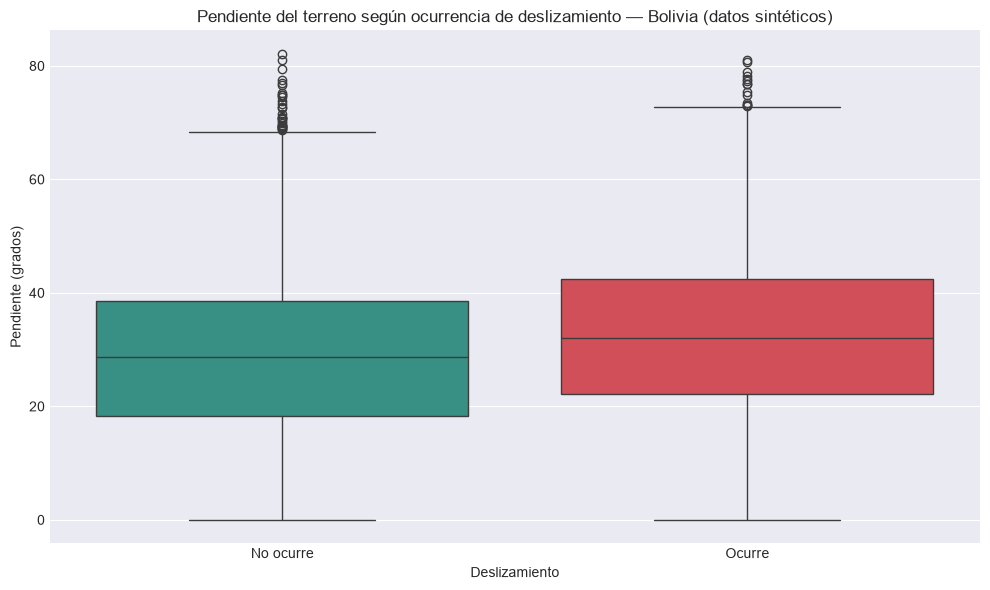

           pendiente_grados  precipitacion_7d_mm  humedad_pct
clase                                                        
No ocurre             28.71                88.58        58.39
Ocurre                32.06               114.94        61.04


In [19]:
# Boxplot de pendiente por clase de deslizamiento (Opción A) para ver si la pendiente separa las clases
df['clase'] = df[columna_objetivo].map(dict(enumerate(NOMBRES_CLASES)))
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='clase', y='pendiente_grados', order=NOMBRES_CLASES,
            hue='clase', palette=dict(zip(NOMBRES_CLASES, COLORES_CLASES.values())), legend=False)
plt.title('Pendiente del terreno según ocurrencia de deslizamiento — Bolivia (datos sintéticos)')
plt.xlabel('Deslizamiento')
plt.ylabel('Pendiente (grados)')
plt.tight_layout(); plt.show()
print(df.groupby('clase')[['pendiente_grados', 'precipitacion_7d_mm', 'humedad_pct']].median().round(2))

**Patrón:** la mediana de pendiente es visiblemente mayor en los registros con deslizamiento (ver medianas impresas), aunque las cajas se solapan bastante: la pendiente es informativa pero **no basta por sí sola** para separar las clases.

**Por qué importa:** coincide con la física de las laderas (a mayor pendiente, mayor esfuerzo cortante sobre el suelo), lo que da confianza en que el dataset sintético captura una relación realista, y orienta a Defensa Civil a priorizar el monitoreo en laderas empinadas. El solapamiento anticipa por qué el modelo necesitará combinar pendiente con lluvia y humedad.

## 6. Variable objetivo para clasificación

deslizamiento_ocurrido
0    5618
1    4382
Name: count, dtype: int64


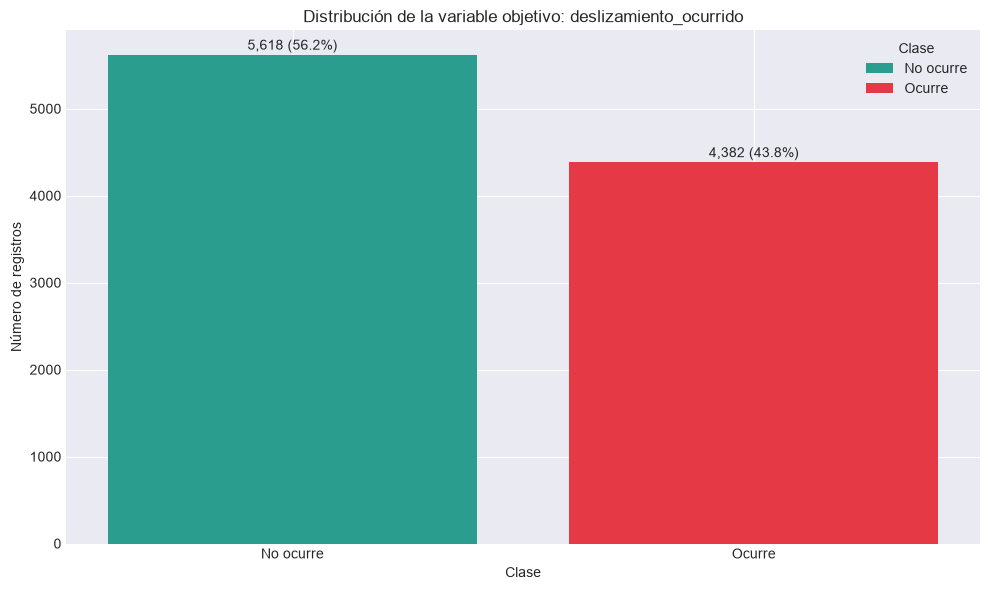

In [20]:
# Gráfico de barras de la distribución de la variable objetivo (orden lógico: No ocurre, Ocurre)
conteo = df[columna_objetivo].value_counts().sort_index()
print(conteo)
plt.figure(figsize=(10, 6))
barras = plt.bar(NOMBRES_CLASES, conteo.values, color=[COLORES_CLASES[0], COLORES_CLASES[1]])
for b, v in zip(barras, conteo.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 60, f'{v:,} ({v / len(df):.1%})', ha='center')
plt.title('Distribución de la variable objetivo: deslizamiento_ocurrido')
plt.xlabel('Clase'); plt.ylabel('Número de registros')
plt.legend(barras, NOMBRES_CLASES, title='Clase')
plt.tight_layout(); plt.show()

**¿Por qué Random Forest?**
- Maneja clasificación (binaria y multiclase) de forma natural.
- Acepta variables mixtas (numéricas y dummies de categorías) sin supuestos de linealidad ni de distribución.
- Es robusto al ruido y al sobreajuste, al promediar muchos árboles.
- Captura interacciones (p. ej. lluvia × pendiente) sin especificarlas.
- Entrega la importancia de cada variable, útil para explicar el modelo a autoridades.

Las clases tienen un desbalance moderado (≈56/44), por eso se usa `class_weight='balanced'`.

## 7. Separación entrenamiento / prueba

In [21]:
# Muestra las formas de train/test (split replicado de train_model.py) y verifica la proporción 80/20 y la estratificación
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)
print(f'Proporción train/test: {len(X_train) / len(X):.0%} / {len(X_test) / len(X):.0%}')
print('Clase 1 en train: %.3f | en test: %.3f | global: %.3f' % (y_train.mean(), y_test.mean(), y.mean()))

# Demostración de no-leakage: el scaler guardado se ajustó SOLO con train
from sklearn.preprocessing import StandardScaler
sc_check = StandardScaler().fit(X_train)
print('Scaler reproducido == scaler.joblib:', np.allclose(sc_check.mean_, scaler.mean_) and np.allclose(sc_check.scale_, scaler.scale_))

X_train: (8000, 16) | X_test: (2000, 16)
y_train: (8000,) | y_test: (2000,)
Proporción train/test: 80% / 20%
Clase 1 en train: 0.438 | en test: 0.438 | global: 0.438
Scaler reproducido == scaler.joblib: True


**Data leakage:** ocurre cuando información del conjunto de prueba influye en el entrenamiento, inflando artificialmente el desempeño. Para evitarlo:
1. Primero se separa train/test (`random_state=42`, estratificado).
2. El `StandardScaler` se **ajusta (`fit`) solo con train**; en test únicamente se aplica `transform` con la media y desviación de train.
3. SMOTE (sobremuestreo sintético) también se aplica **solo a train**; el conjunto de prueba conserva su distribución real.

La verificación de arriba confirma que el `scaler.joblib` coincide con uno ajustado únicamente sobre `X_train`.

## 8. ¿Cuáles son las variables más importantes?

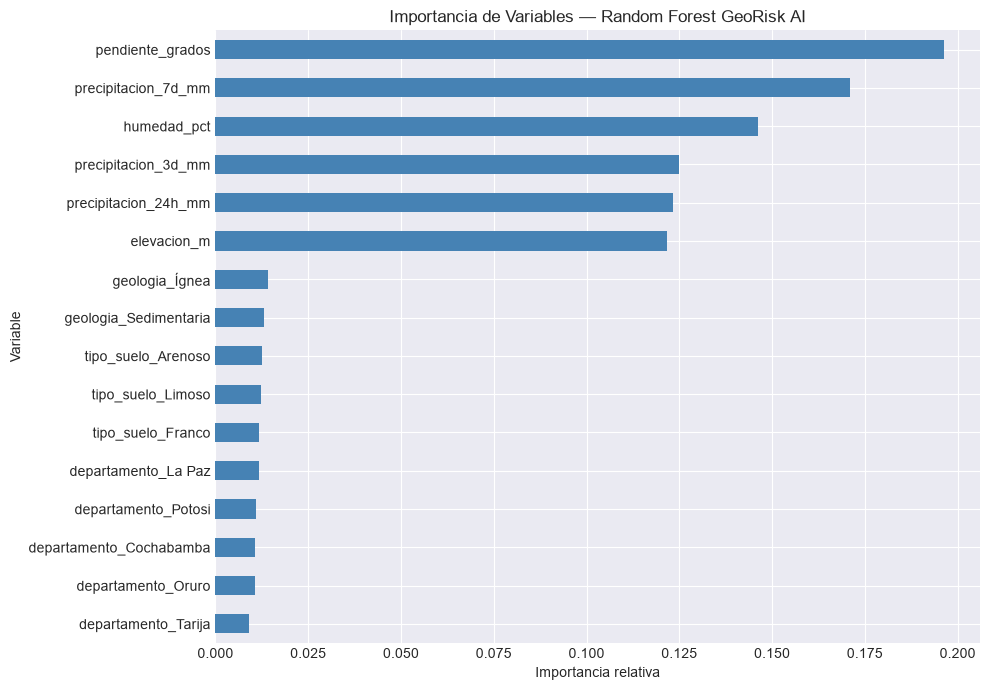

pendiente_grados        0.1962
precipitacion_7d_mm     0.1709
humedad_pct             0.1461
precipitacion_3d_mm     0.1250
precipitacion_24h_mm    0.1234
dtype: float64


In [22]:
# Importancia de variables del Random Forest cargado (reducción media de impureza), ordenada y graficada
importancias = pd.Series(modelo.feature_importances_, index=columnas)
importancias_sorted = importancias.sort_values(ascending=True)

plt.figure(figsize=(10, 7))
importancias_sorted.plot(kind='barh', color='steelblue')
plt.title('Importancia de Variables — Random Forest GeoRisk AI')
plt.xlabel('Importancia relativa')
plt.ylabel('Variable')
plt.tight_layout(); plt.show()
print(importancias.sort_values(ascending=False).head(5).round(4))

**Las 3 variables más importantes** (ver gráfico y tabla):
1. **`pendiente_grados` (≈0.196):** la inclinación de la ladera está asociada al riesgo, lo que es consistente con la física de deslizamientos: en laderas más empinadas la gravedad aporta más esfuerzo cortante.
2. **`precipitacion_7d_mm` (≈0.171):** la lluvia acumulada de una semana está asociada al riesgo; es consistente con que el suelo saturado pierde resistencia y aumenta la presión de poros.
3. **`humedad_pct` (≈0.146):** una mayor humedad del suelo se asocia con más riesgo, de forma coherente con la saturación previa a un evento.

**Cautela:** la importancia indica *asociación* dentro del modelo, **no causalidad**. Además, las importancias están bastante repartidas (las 3 de precipitación y la elevación rondan 0.12–0.17), lo que indica que ninguna variable domina por sí sola.

## 9. Desempeño en el conjunto de prueba

              precision    recall  f1-score   support

   No ocurre      0.630     0.607     0.618      1124
      Ocurre      0.518     0.542     0.530       876

    accuracy                          0.579      2000
   macro avg      0.574     0.574     0.574      2000
weighted avg      0.581     0.579     0.579      2000

Accuracy: 0.5785 | F1-macro: 0.5739


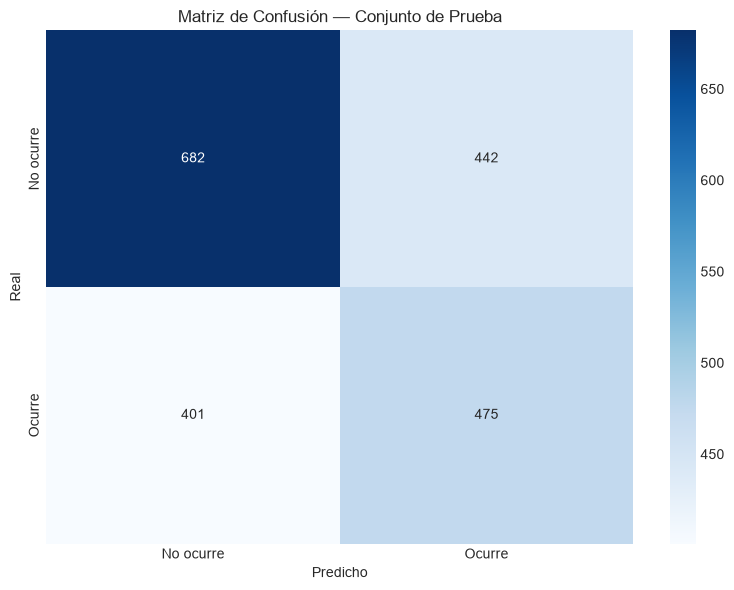

Falsos negativos (real=Ocurre, predicho=No ocurre): 401 de 876 eventos (45.8%)


In [23]:
# Reporte de clasificación y matriz de confusión del modelo cargado sobre el test (preprocesado con el scaler cargado)
print(classification_report(y_test, y_pred, target_names=NOMBRES_CLASES, digits=3))
acc = accuracy_score(y_test, y_pred)
f1m = f1_score(y_test, y_pred, average='macro')
print(f'Accuracy: {acc:.4f} | F1-macro: {f1m:.4f}')

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES)
plt.title('Matriz de Confusión — Conjunto de Prueba')
plt.ylabel('Real'); plt.xlabel('Predicho')
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'Falsos negativos (real=Ocurre, predicho=No ocurre): {fn} de {fn + tp} eventos ({fn / (fn + tp):.1%})')

**Resultados:** accuracy ≈ **0.579** y F1-macro ≈ **0.574** sobre 2000 registros de prueba. El desempeño es **modesto**: solo ligeramente superior al azar informado (≈56 % por predecir siempre *No ocurre*). El modelo detecta ≈54 % de los eventos reales (recall de *Ocurre*).

**Error más crítico:** el **falso negativo** — predecir *No ocurre* (zona segura) cuando sí hay riesgo real — puede costar vidas porque no se emite alerta ni evacuación. Aquí son ≈401 de 876 eventos. Reducirlos (p. ej. bajando el umbral de decisión de `predict_proba` o priorizando recall de *Ocurre*) a costa de más falsas alarmas sería preferible en un sistema de alerta temprana.

## 10. Visualización de un árbol de decisión

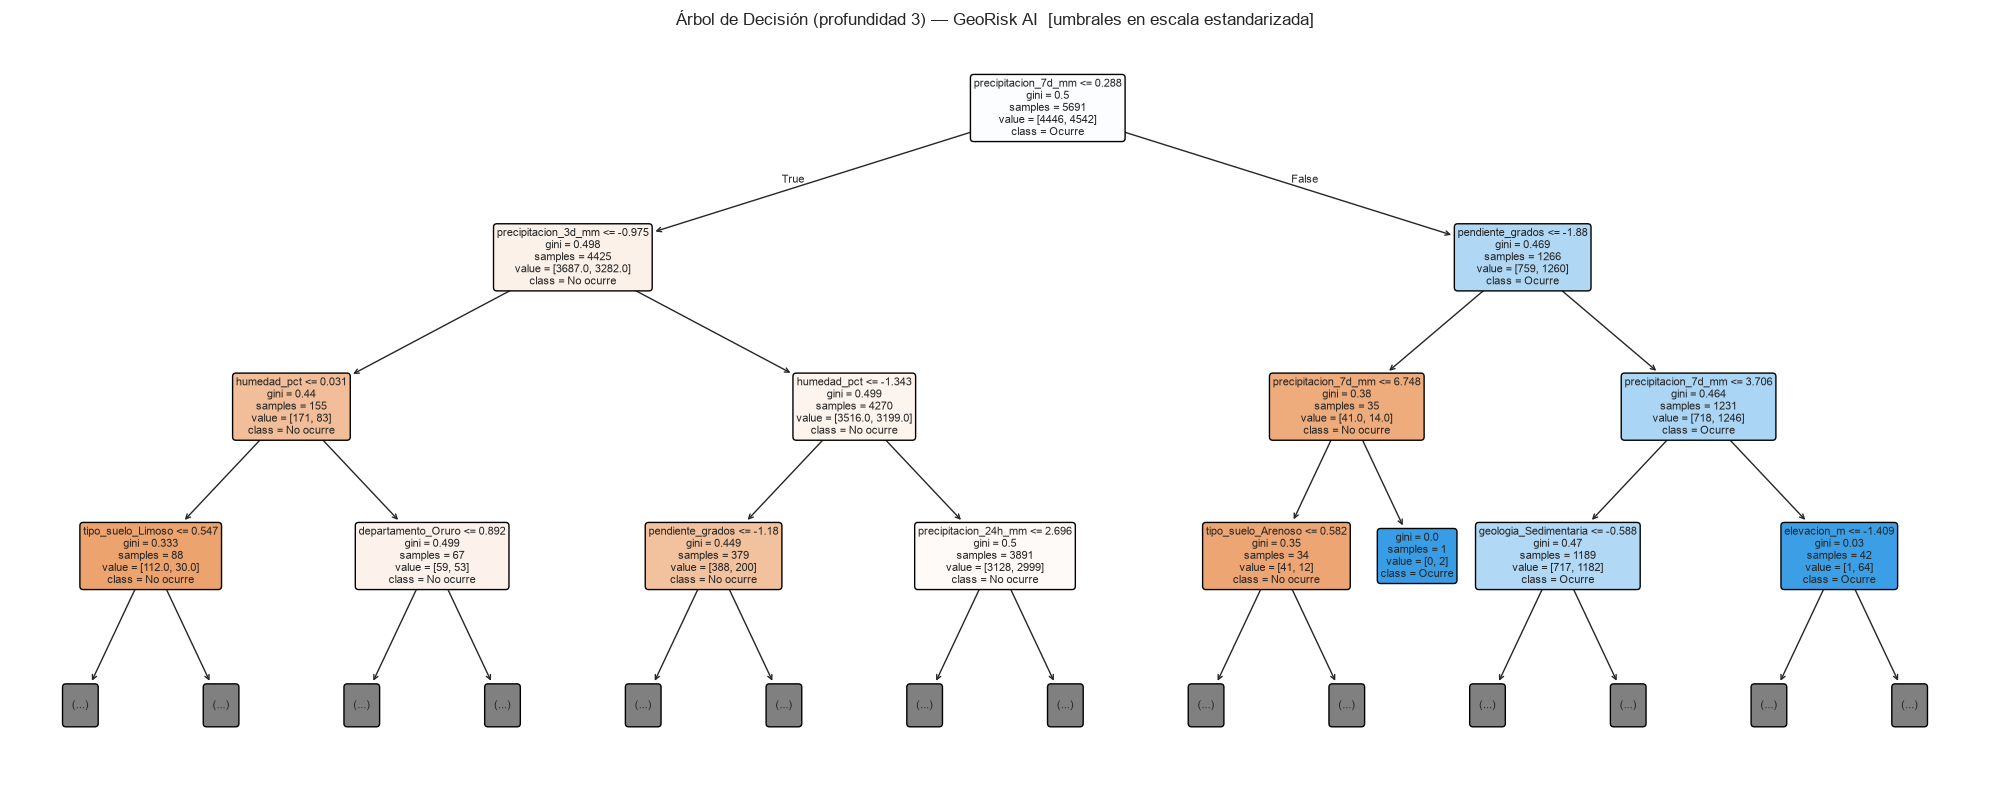

Ruta (siempre por la rama "<="):
  precipitacion_7d_mm <= 240.9   (estandarizado 0.288)
  precipitacion_3d_mm <= 1.6   (estandarizado -0.975)
  humedad_pct <= 60.2   (estandarizado 0.031)
  -> proporción de clases en ese nodo [No ocurre, Ocurre]: [0.79 0.21]


In [24]:
# Dibuja el primer árbol del Random Forest limitado a profundidad 3 e imprime la ruta raíz->hoja con umbrales en unidades reales
from sklearn.tree import plot_tree

un_arbol = modelo.estimators_[0]
plt.figure(figsize=(20, 8))
plot_tree(un_arbol, max_depth=3, feature_names=columnas, class_names=NOMBRES_CLASES,
          filled=True, fontsize=8, rounded=True)
plt.title('Árbol de Decisión (profundidad 3) — GeoRisk AI  [umbrales en escala estandarizada]')
plt.tight_layout(); plt.show()

# Los umbrales del árbol están estandarizados: se convierten a unidades reales con la media/desv. del scaler
t = un_arbol.tree_
idx = {c: i for i, c in enumerate(columnas)}
nodo = 0
print('Ruta (siempre por la rama "<="):')
for _ in range(3):
    f = t.feature[nodo]; nombre = columnas[f]; thr = t.threshold[nodo]
    if f < len(scaler.mean_) and nombre in VARS_NUM:
        thr_real = thr * scaler.scale_[f] + scaler.mean_[f]
        print(f'  {nombre} <= {thr_real:.1f}   (estandarizado {thr:.3f})')
    else:
        print(f'  {nombre} <= {thr:.3f}   (dummy 0/1 estandarizada: "no" es la rama <=)')
    nodo = t.children_left[nodo]
print('  -> proporción de clases en ese nodo [No ocurre, Ocurre]:', t.value[nodo][0].round(2))

**Interpretación de una ruta (raíz → hoja, rama izquierda):**
> Si la **precipitación acumulada de 7 días ≤ ≈241 mm**, **y** la precipitación de 3 días es muy baja (≈2 mm o menos), **y** la **humedad del suelo ≤ ≈60 %**, entonces el árbol se inclina por **No ocurre** (≈79 % de las muestras de ese nodo): una semana poco lluviosa con suelo no saturado no activa la ladera.

La lectura opuesta (más lluvia acumulada y suelo más húmedo → más probabilidad de *Ocurre*) es la que activaría una alerta.

**Qué aporta la visualización:** permite ver *cómo* decide el modelo —qué variables usa primero y con qué umbrales— y contrastarlo con el criterio de geólogos y Defensa Civil. Es una muestra de **un solo árbol de 100** y truncado a profundidad 3: ilustra la lógica, no reemplaza al bosque completo. Los umbrales están en escala estandarizada y aquí se convirtieron a unidades reales.

## CONCLUSIONES FINALES

**3 hallazgos principales**
1. **Las variables más asociadas al riesgo son la pendiente (≈0.20), la precipitación acumulada de 7 días (≈0.17) y la humedad (≈0.15)**, coherentes con la física de deslizamientos; las importancias están repartidas, sin una variable dominante.
2. **El desempeño del Random Forest es modesto:** accuracy ≈ 0.58 y F1-macro ≈ 0.57 en test; detecta ≈54 % de los eventos reales y deja pasar ≈46 % (falsos negativos).
3. **El dataset es limpio** (sin nulos, duplicados ni valores fuera de rango) y moderadamente desbalanceado (≈56/44); el preprocesamiento evita data leakage (split → scaler y SMOTE solo en train).

**Recomendación práctica para Defensa Civil y municipios:** usar el modelo solo como **apoyo de priorización**, no como decisor único: ajustar el umbral de probabilidad para maximizar el recall de *Ocurre* (aceptando más falsas alarmas) y combinarlo con los umbrales de lluvia acumulada y pendiente en un protocolo de alerta escalonado, con verificación en campo antes de ordenar evacuaciones.

**Limitaciones**
- Datos **sintéticos**: el desempeño real puede ser muy distinto; es indispensable **validar con datos reales** (inventarios de deslizamientos del SERGEOTECMIN, registros del SENAMHI y de Defensa Civil).
- Desempeño actual insuficiente para un sistema de alerta autónomo; falta ajuste de hiperparámetros, validación cruzada y calibración de probabilidades.
- Sin dimensión temporal ni espacial fina (coordenadas, cobertura vegetal, sismicidad, intervención humana).
- Las importancias y árboles muestran asociaciones, **no causalidad**.